# Chuva: integração e efeito nos modelos

**Projeto Integrador IV (UNIVESP).** Continuação de `02_modelos_base.ipynb`.

A análise exploratória mostrou picos de ocorrências no verão e apontou a chuva como a variável que faltava. Este notebook:

1. integra a chuva diária observada pelo INMET;
2. mede a relação entre chuva e ocorrências: quanto, com que atraso e em quais grupos;
3. reavalia os dois modelos com variáveis de chuva, **com o mesmo protocolo do notebook 02** (escolhas na validação, teste usado uma vez) e com intervalos de confiança para as diferenças.

O código está em `ml/chuva.py` (download e agregação) e `ml/features.py` (variáveis).

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("defesa2.0").exists():
        !git clone -q https://github.com/allanwds/defesa2.0.git
    RAIZ = Path("defesa2.0").resolve()
else:
    RAIZ = Path.cwd().resolve()
    while not (RAIZ / "ml").is_dir() and RAIZ != RAIZ.parent:
        RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, log_loss, recall_score

from ml import modelos as M
from ml.chuva import ESTACAO, chuva_diaria
from ml.dados import carregar_ocorrencias
from ml.features import (CHUVA_OCORRENCIA, CHUVA_SEMANA_ANTERIOR, CHUVA_SEMANA_PREVISTA, VARIAVEIS_CLASSIFICACAO,
                         VARIAVEIS_REGRESSAO, adicionar_chuva_ocorrencias, adicionar_chuva_painel, painel_semanal,
                         tabela_classificacao)
from ml.limpeza import PERIODOS_COMPLETOS, limpar, marcar_periodos, ocorrencias_validas

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

TEXTO, TEXTO_SEC, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
AZUL, CINZA = "#2a78d6", "#c9c8c2"
CORES_GRUPO = {"Estrutural": "#2a78d6", "Arbóreo": "#eb6834", "Geológico": "#1baf7a", "Hidrológico": "#eda100",
               "Outros": "#8a8984"}
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO_SEC,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SEC,
    "ytick.color": TEXTO_SEC,
    "legend.frameon": False,
    "font.size": 10,
})


def eixo_meses(ax):
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: MESES[mdates.num2date(x).month - 1]))


def num(v, casas=2):
    return f"{v:.{casas}f}".replace(".", ",")


INICIO_VALIDACAO = pd.Timestamp("2025-04-01")
INICIO_TESTE = pd.Timestamp("2025-07-01")

## 1. Fonte dos dados

| Fonte | Situação |
|---|---|
| **INMET, estação automática A771 (São Paulo – Interlagos)** | **Usada.** Dados horários públicos no BDMEP (`portal.inmet.gov.br/dadoshistoricos`). A estação fica a cerca de 9 km do centro das ocorrências |
| CEMADEN, pluviômetros automáticos | Tem estações **dentro** de M'Boi Mirim, mas o download exige cadastro e aprovação de cada pedido na plataforma PED (`ped.cemaden.gov.br`) |
| CGE-SP (Prefeitura) | Não tem download de dados aberto; publica boletins e mapas |
| API do INMET (`apitempo.inmet.gov.br`) | Passou a exigir token |

Os arquivos anuais do BDMEP têm mais de 100 MB, com todas as estações do país. `ml/chuva.py` baixa só o trecho da A771 (algumas centenas de KB por ano), usando download parcial do zip.

**Pluviômetros do CEMADEN na região** (códigos da lista pública de estações):

| Código | Nome | Latitude | Longitude |
|---|---|---|---|
| 355030824A | Jardim Angela | -23,697 | -46,765 |
| 355030809A | Jardim São Luis | -23,667 | -46,728 |
| 355030858A | Jardim Vera Cruz | -23,736 | -46,781 |
| 355030863A | Capão Redondo2 | -23,674 | -46,770 |
| 355030814A | Vila das Belezas | -23,647 | -46,744 |

Com esses pluviômetros, cada ocorrência poderia receber a chuva medida a poucas centenas de metros, em vez de a 9 km.

In [2]:
oc = marcar_periodos(ocorrencias_validas(limpar(carregar_ocorrencias())))
diaria = chuva_diaria([2024, 2025, 2026])

centro = oc[["latitude", "longitude"]].median()
A771 = (-23.72444443, -46.67749999)
dist_km = 6371 * np.hypot(np.radians(centro["latitude"] - A771[0]),
                          np.radians(centro["longitude"] - A771[1]) * np.cos(np.radians(A771[0])))
print(f"Estação {ESTACAO}: {dist_km:.1f} km do ponto mediano das ocorrências")
print(f"Chuva diária de {diaria['data'].min():%d/%m/%Y} a {diaria['data'].max():%d/%m/%Y}: {len(diaria)} dias, "
      f"{diaria['chuva_mm'].isna().sum()} sem total (falha de medição)")

Estação A771: 9.3 km do ponto mediano das ocorrências
Chuva diária de 31/12/2023 a 31/08/2026: 975 dias, 2 sem total (falha de medição)


## 2. A série de chuva

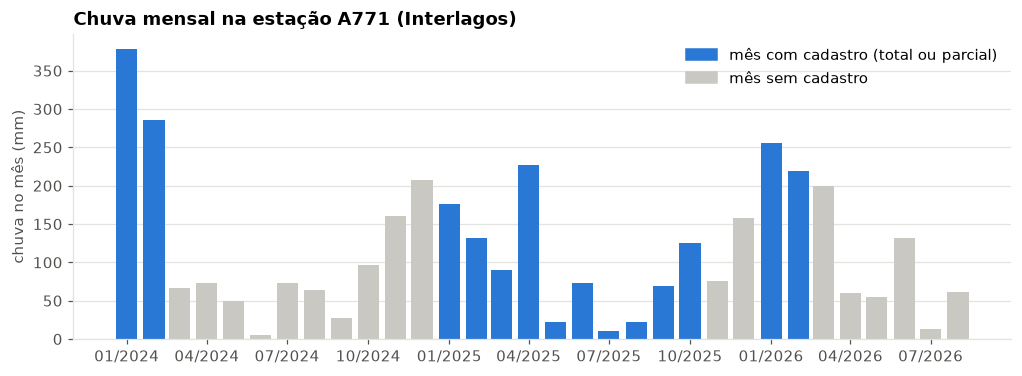

,data,chuva_mm
12,12/01/2024,92.400
746,15/01/2026,68.600
13,13/01/2024,62.200
399,02/02/2025,60.400
763,01/02/2026,59.200
905,23/06/2026,55.200


In [3]:
diaria_periodo = diaria[diaria["data"] >= "2024-01-01"]
mensal = diaria_periodo.groupby(diaria_periodo["data"].dt.to_period("M"))["chuva_mm"].sum()
coberto = pd.Series(False, index=mensal.index)
for inicio, fim in PERIODOS_COMPLETOS:
    coberto[(mensal.index >= pd.Period(inicio, "M")) & (mensal.index <= pd.Period(fim, "M"))] = True

fig, ax = plt.subplots(figsize=(11, 3.6))
x = mensal.index.to_timestamp()
ax.bar(x, mensal.values, width=24, color=np.where(coberto, AZUL, CINZA))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_ylabel("chuva no mês (mm)")
ax.set_title(f"Chuva mensal na estação {ESTACAO} (Interlagos)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=CINZA)],
          labels=["mês com cadastro (total ou parcial)", "mês sem cadastro"], loc="upper right")
plt.show()

diaria.nlargest(6, "chuva_mm")[["data", "chuva_mm"]].assign(data=lambda t: t["data"].dt.strftime("%d/%m/%Y"))

A série está praticamente completa e mostra o ciclo esperado: verões chuvosos (de 200 a 380 mm por mês) e invernos secos. Os meses com cadastro (em azul) cobrem os dois regimes, mas o **período de teste** dos modelos (julho a setembro de 2025) cai na parte mais seca do ano. Isso limita o quanto a chuva pode ajudar justamente no teste.

## 3. Chuva e ocorrências

### 3.1 Semana a semana

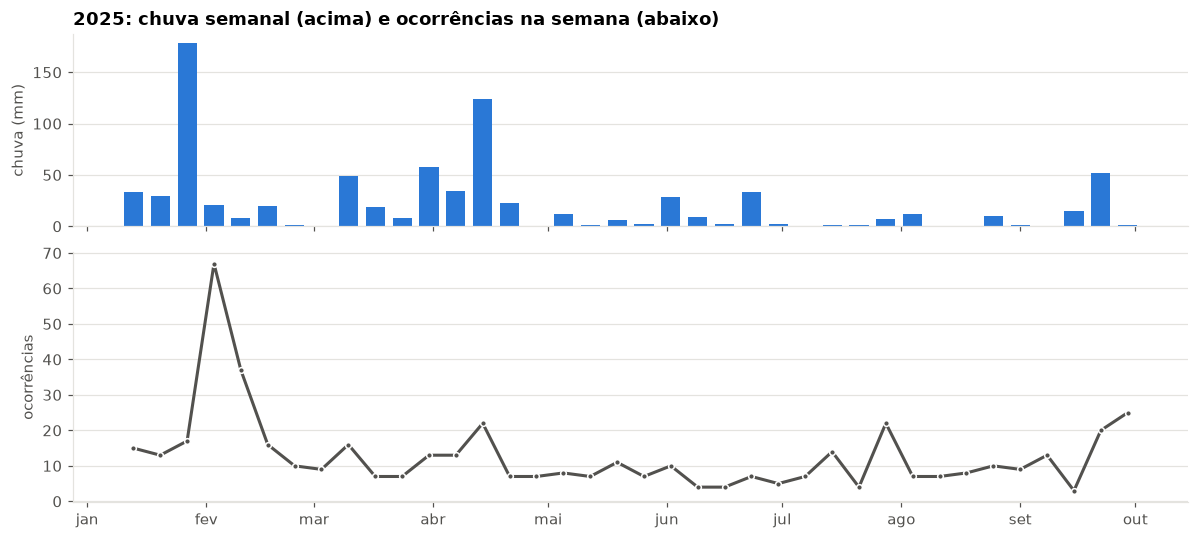

In [4]:
painel = adicionar_chuva_painel(painel_semanal(oc), diaria)
semanal = painel.groupby("semana").agg(ocorrencias=("ocorrencias", "sum"), chuva=("chuva_sem", "first"))
s25 = semanal[semanal.index.year == 2025]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
ax1.bar(s25.index, s25["chuva"], width=5, color=AZUL)
ax1.set_ylabel("chuva (mm)")
ax1.set_title("2025: chuva semanal (acima) e ocorrências na semana (abaixo)")
ax2.plot(s25.index, s25["ocorrencias"], color=TEXTO_SEC, linewidth=2)
ax2.scatter(s25.index, s25["ocorrencias"], s=14, color=TEXTO_SEC, edgecolor="white", linewidth=1, zorder=3)
ax2.set_ylabel("ocorrências")
eixo_meses(ax2)
fig.tight_layout()
plt.show()

O maior pico de ocorrências (semana de 3 de fevereiro) vem **depois** da semana mais chuvosa de janeiro e fevereiro (178 mm, com 60 mm só no dia 2). A semana do pico em si teve pouca chuva. Isso confirma o que a análise exploratória sugeria: a data cadastrada é a do atendimento, que acontece dias depois do evento.

### 3.2 Com quantos dias de atraso?

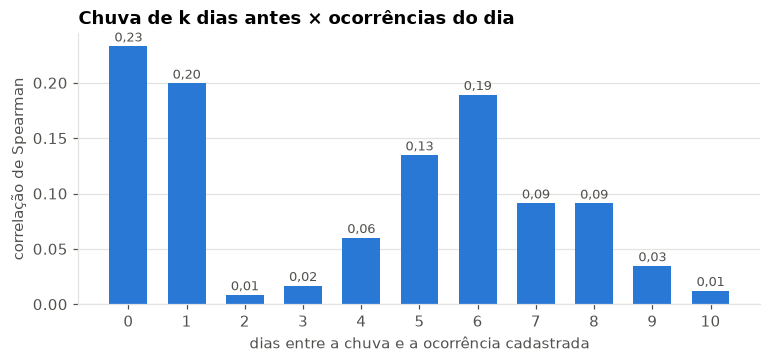

In [5]:
dias = pd.DatetimeIndex(np.concatenate([pd.date_range(i, f) for i, f in PERIODOS_COMPLETOS]))
por_dia = oc.groupby("data").size().reindex(dias, fill_value=0)
chuva_dia = diaria.set_index("data")["chuva_mm"]

defasagens = range(0, 11)
correlacao = pd.Series([por_dia.corr(chuva_dia.shift(k).reindex(dias), method="spearman") for k in defasagens],
                       index=defasagens)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(correlacao.index, correlacao.values, width=0.65, color=AZUL)
for k, v in correlacao.items():
    ax.annotate(num(v), (k, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, color=TEXTO_SEC)
ax.set_xticks(list(defasagens))
ax.set_xlabel("dias entre a chuva e a ocorrência cadastrada")
ax.set_ylabel("correlação de Spearman")
ax.set_title("Chuva de k dias antes × ocorrências do dia")
plt.show()

- A correlação é maior com a chuva do **próprio dia e do dia anterior**, cai a quase zero com 2 a 4 dias de distância e volta a subir com 5 e 6 dias.
- Esse segundo pico combina com um atendimento em escala semanal: parte das ocorrências de um temporal é vistoriada na semana seguinte.
- Na prática, a chuva acumulada numa janela de vários dias capta melhor a relação do que a chuva de um único dia.

### 3.3 Semanas depois de chuva forte

Para medir o tamanho do efeito, as semanas são divididas pela chuva acumulada em 14 dias (a semana e a anterior). O limite de 50 mm foi definido antes da análise.

In [6]:
semanal["chuva_14d"] = semanal["chuva"] + painel.groupby("semana")["chuva_sem_ant"].first()
forte = semanal["chuva_14d"] >= 50
razao = semanal.loc[forte, "ocorrencias"].mean() / semanal.loc[~forte, "ocorrencias"].mean()

rng = np.random.default_rng(M.SEMENTE)
a, b = semanal.loc[forte, "ocorrencias"].to_numpy(), semanal.loc[~forte, "ocorrencias"].to_numpy()
razoes = [rng.choice(a, len(a)).mean() / rng.choice(b, len(b)).mean() for _ in range(5000)]
ic = np.quantile(razoes, [0.025, 0.975])

print(pd.DataFrame({
    "semanas": [forte.sum(), (~forte).sum()],
    "ocorrências por semana (média)": [a.mean(), b.mean()],
}, index=["≥ 50 mm em 14 dias", "< 50 mm em 14 dias"]).round(1).to_string())
print(f"\nRazão: {num(razao)} (intervalo de 95%: {num(ic[0])} a {num(ic[1])})")

                    semanas  ocorrências por semana (média)
≥ 50 mm em 14 dias       20                          20.400
< 50 mm em 14 dias       28                          10.100

Razão: 2,01 (intervalo de 95%: 1,40 a 2,88)


Depois de 50 mm ou mais em duas semanas, o volume de ocorrências **praticamente dobra**, e o intervalo de confiança fica bem acima de 1. A relação entre chuva e demanda é real e grande.

### 3.4 Chuva antes de cada tipo de ocorrência

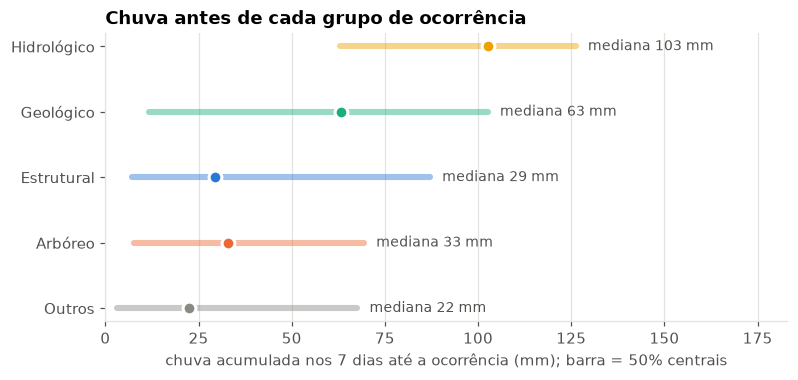

In [7]:
tabela = adicionar_chuva_ocorrencias(tabela_classificacao(oc), diaria)
ordem = ["Hidrológico", "Geológico", "Estrutural", "Arbóreo", "Outros"]
q = tabela.groupby("grupo_motivo")["chuva_7d"].quantile([0.25, 0.5, 0.75]).unstack().reindex(ordem)

fig, ax = plt.subplots(figsize=(8, 3.4))
for y, (grupo, linha) in enumerate(q.iterrows()):
    ax.plot([linha[0.25], linha[0.75]], [y, y], color=CORES_GRUPO[grupo], linewidth=4, solid_capstyle="round", alpha=0.45)
    ax.scatter(linha[0.5], y, s=70, color=CORES_GRUPO[grupo], edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f"mediana {linha[0.5]:.0f} mm", (linha[0.75], y), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=TEXTO_SEC)
ax.set_yticks(range(len(ordem)), ordem)
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, q[0.75].max() * 1.45)
ax.set_xlabel("chuva acumulada nos 7 dias até a ocorrência (mm); barra = 50% centrais")
ax.set_title("Chuva antes de cada grupo de ocorrência")
plt.show()

- As ocorrências **hidrológicas** acontecem depois de muito mais chuva (mediana perto de 100 mm em 7 dias), seguidas das **geológicas**.
- Estrutural, Arbóreo e Outros ficam em patamares parecidos e mais baixos.

A chuva deveria, portanto, ajudar a separar justamente os grupos que o modelo do notebook 02 tinha mais dificuldade de reconhecer.

## 4. Regressão com chuva

Três versões, todas com o mesmo protocolo do notebook 02 (hiperparâmetro escolhido na validação, teste passo a passo):

| Versão | Variáveis de chuva | Uso prático |
|---|---|---|
| sem chuva | nenhuma (modelo do notebook 02) | possível |
| chuva da semana anterior | total e maior dia da semana anterior | possível: a chuva já aconteceu |
| previsão perfeita | as anteriores mais total e maior dia **da própria semana** | só com previsão do tempo. Aqui usa a chuva observada, por isso mede o **ganho máximo** de uma previsão perfeita |

Só as duas primeiras usam apenas informação disponível no momento da previsão. A terceira é um cenário de referência.

In [8]:
VERSOES_REG = {
    "sem chuva": VARIAVEIS_REGRESSAO,
    "chuva da semana anterior": VARIAVEIS_REGRESSAO + CHUVA_SEMANA_ANTERIOR,
    "previsão perfeita": VARIAVEIS_REGRESSAO + CHUVA_SEMANA_ANTERIOR + CHUVA_SEMANA_PREVISTA,
}
res_reg = {nome: M.avaliar_regressao(painel, variaveis, INICIO_VALIDACAO, INICIO_TESTE)
           for nome, variaveis in VERSOES_REG.items()}

base = res_reg["sem chuva"]["teste"]
erro_base = (base["ocorrencias"] - base["previsto"]).abs().to_numpy()
linhas = []
for nome, r in res_reg.items():
    erro = (r["teste"]["ocorrencias"] - r["teste"]["previsto"]).abs().to_numpy()
    if nome == "sem chuva":
        ic = (np.nan, np.nan)
    else:
        ic = M.intervalo_bootstrap(lambda i: erro[i].mean() - erro_base[i].mean(), len(erro), grupos=base["semana"])
    linhas.append({"versão": nome, "min_samples_leaf": r["min_samples_leaf"], "MAE validação": r["mae_validacao"],
                   "MAE teste": r["metricas_teste"]["MAE"], "RMSE teste": r["metricas_teste"]["RMSE"],
                   "diferença de MAE vs. sem chuva (IC 95%)": "" if nome == "sem chuva" else
                   f"{num(erro.mean() - erro_base.mean())} [{num(ic[0])}; {num(ic[1])}]"})
tabela_reg = pd.DataFrame(linhas).set_index("versão")

operacionais = ["sem chuva", "chuva da semana anterior"]
escolhida_reg = min(operacionais, key=lambda n: res_reg[n]["mae_validacao"])
print(f"Escolhida para uso (menor MAE na validação entre as versões possíveis): {escolhida_reg}")
tabela_reg

Escolhida para uso (menor MAE na validação entre as versões possíveis): sem chuva


,min_samples_leaf,MAE validação,MAE teste,RMSE teste,diferença de MAE vs. sem chuva (IC 95%)
versão,,,,,
sem chuva,10,3.217,3.172,4.219,
chuva da semana anterior,10,3.266,3.276,4.224,"0,10 [-0,17; 0,42]"
previsão perfeita,1,2.578,3.091,4.107,"-0,08 [-0,82; 0,69]"


O intervalo de confiança da diferença foi calculado por *bootstrap* pareado, sorteando semanas inteiras. Valores negativos significam que a versão com chuva erra menos.

- **Chuva da semana anterior:** não melhora a previsão. O erro fica um pouco maior, e o intervalo inclui o zero. A versão sem chuva continua sendo a escolhida.
- **Previsão perfeita:** é a melhor na validação e erra um pouco menos no teste, mas o intervalo de confiança também inclui o zero.

Mesmo sabendo exatamente quanto vai chover na semana, o ganho não é detectável com 32 previsões de teste, quase todas em semanas secas.

Por que a chuva, que dobra a demanda (seção 3.3), não melhora o modelo? As defasagens (`lag1`, `total_lag1`) já carregam boa parte dessa informação: os episódios de chuva duram semanas, e uma semana movimentada tende a ser seguida de outra. A chuva acrescentaria informação nova principalmente no **início** de um episódio chuvoso, e o teste quase não tem esses momentos.

## 5. Classificação com chuva

A pergunta aqui é qual janela de chuva usar. Cada conjunto de variáveis é tratado como mais uma escolha feita **na validação**: o conjunto e os hiperparâmetros com maior F1 macro na validação seguem para o teste.

In [9]:
VERSOES_CLS = {
    "sem chuva": VARIAVEIS_CLASSIFICACAO,
    "+ chuva 7 dias": VARIAVEIS_CLASSIFICACAO + ["chuva_7d"],
    "+ chuva 3 e 7 dias": VARIAVEIS_CLASSIFICACAO + ["chuva_3d", "chuva_7d"],
    "+ chuva 1, 3 e 7 dias": VARIAVEIS_CLASSIFICACAO + CHUVA_OCORRENCIA,
}
res_cls = {nome: M.avaliar_classificacao(tabela, variaveis, INICIO_VALIDACAO, INICIO_TESTE)
           for nome, variaveis in VERSOES_CLS.items()}

teste = tabela[tabela["data"] >= INICIO_TESTE]
y = teste["grupo_motivo"].to_numpy()
classes = res_cls["sem chuva"]["modelo"].classes_
ref = res_cls["sem chuva"]

linhas = []
for nome, r in res_cls.items():
    linha = {"versão": nome, "min_samples_leaf": r["min_samples_leaf"], "max_features": r["max_features"] or "todas",
             "F1 macro validação": r["f1_validacao"], **{f"{k} teste": v for k, v in r["metricas_teste"].items()}}
    linhas.append(linha)
tabela_cls = pd.DataFrame(linhas).set_index("versão")

escolhida_cls = max(res_cls, key=lambda n: res_cls[n]["f1_validacao"])
print(f"Escolhida (maior F1 macro na validação): {escolhida_cls}")
tabela_cls

Escolhida (maior F1 macro na validação): + chuva 3 e 7 dias


,min_samples_leaf,max_features,F1 macro validação,acurácia teste,acurácia balanceada teste,F1 macro teste,log loss teste
versão,,,,,,,
sem chuva,10,todas,0.287,0.326,0.323,0.281,1.389
+ chuva 7 dias,3,sqrt,0.282,0.387,0.364,0.350,1.375
+ chuva 3 e 7 dias,1,sqrt,0.290,0.344,0.309,0.316,1.501
"+ chuva 1, 3 e 7 dias",3,todas,0.256,0.330,0.327,0.309,1.481


In [10]:
r = res_cls[escolhida_cls]
ic_f1 = M.intervalo_bootstrap(lambda i: f1_score(y[i], r["previsto"][i], average="macro")
                              - f1_score(y[i], ref["previsto"][i], average="macro"), len(y))
ic_ll = M.intervalo_bootstrap(lambda i: log_loss(y[i], r["probabilidades"][i], labels=classes)
                              - log_loss(y[i], ref["probabilidades"][i], labels=classes), len(y))
print(f"'{escolhida_cls}' menos 'sem chuva', no teste (IC 95% por bootstrap pareado):")
print(f"  F1 macro: {num(r['metricas_teste']['F1 macro'] - ref['metricas_teste']['F1 macro'], 3)} "
      f"[{num(ic_f1[0], 3)}; {num(ic_f1[1], 3)}]   (positivo = melhor)")
print(f"  log loss: {num(r['metricas_teste']['log loss'] - ref['metricas_teste']['log loss'], 3)} "
      f"[{num(ic_ll[0], 3)}; {num(ic_ll[1], 3)}]   (negativo = melhor)")

pd.DataFrame({
    "sem chuva": recall_score(y, ref["previsto"], labels=classes, average=None),
    escolhida_cls: recall_score(y, r["previsto"], labels=classes, average=None),
}, index=classes).rename_axis("revocação no teste").style.format("{:.0%}")

'+ chuva 3 e 7 dias' menos 'sem chuva', no teste (IC 95% por bootstrap pareado):
  F1 macro: 0,035 [-0,027; 0,095]   (positivo = melhor)
  log loss: 0,112 [0,046; 0,182]   (negativo = melhor)


,sem chuva,+ chuva 3 e 7 dias
revocação no teste,,
Arbóreo,54%,46%
Estrutural,9%,33%
Geológico,19%,14%
Hidrológico,44%,38%
Outros,36%,24%


- Na validação, os quatro conjuntos ficam muito próximos (F1 macro entre 0,26 e 0,29). Com 117 ocorrências de validação, essas diferenças estão dentro do ruído.
- O conjunto escolhido (chuva de 3 e 7 dias) melhora muito a revocação do grupo **Estrutural** (de 9% para 33%), mas piora a de todos os outros. O ganho de F1 macro no teste **não é estatisticamente significativo**: o intervalo inclui o zero.
- As **probabilidades pioram de forma significativa** (log loss maior, intervalo todo acima de zero). Com mais variáveis, a validação escolheu árvores menos regularizadas, que ficam confiantes demais.

Uma observação de transparência: no teste, o conjunto só com a chuva de 7 dias teve o melhor resultado de todos. Escolhê-lo agora, porém, seria usar o teste para decidir, e o número obtido deixaria de valer como estimativa honesta. Ele fica registrado como hipótese para quando houver mais dados de validação.

## 6. Conclusões

### O que a chuva mostra

1. **A relação com a demanda é forte.** As semanas com 50 mm ou mais de chuva em 14 dias têm o dobro de ocorrências (razão 2,0, intervalo de 95% de 1,4 a 2,9).
2. **As ocorrências aparecem com atraso.** Elas se relacionam com a chuva do dia e da véspera e, de novo, com a de 5 a 6 dias antes. A data cadastrada é a do atendimento, não a do evento.
3. **Cada grupo responde de um jeito.** As ocorrências hidrológicas (mediana de 103 mm em 7 dias) e geológicas (63 mm) acontecem depois de muito mais chuva que as demais.

### O que a chuva muda nos modelos

| Modelo | Melhor versão com chuva | Diferença no teste (IC 95%) | Decisão |
|---|---|---|---|
| Regressão semanal | chuva da semana anterior | MAE +0,10 [-0,17; 0,42] | manter sem chuva |
| Regressão semanal (cenário) | previsão perfeita da semana | MAE -0,08 [-0,82; 0,69] | sem ganho detectável |
| Classificação | chuva de 3 e 7 dias | F1 macro +0,035 [-0,03; 0,10]; log loss +0,11 [0,05; 0,18] | manter sem chuva |

Nenhuma versão com chuva melhora os modelos de forma estatisticamente detectável, e a classificação ainda perde qualidade nas probabilidades. **Os modelos do notebook 02, sem chuva, continuam sendo os de melhor desempenho.**

### Por que o sinal não chega aos modelos

- **Teste seco:** o período de teste (julho a setembro) quase não tem chuva, justamente quando ela faria diferença.
- **Defasagens:** as contagens das semanas anteriores já captam os episódios de chuva, que duram semanas.
- **Estação distante:** a estação fica a 9 km, e as chuvas de verão são localizadas.
- **Data do atendimento:** como a data cadastrada é a do atendimento, a ligação dia a dia entre chuva e ocorrência fica diluída.
- **Pouco dado:** são 117 ocorrências de validação e 32 previsões semanais de teste.

### Síntese

A chuva explica uma parte grande da variação da demanda. Transformar essa relação em previsão, porém, exige dados mais finos no espaço (pluviômetros locais) e no tempo (data do chamado), além de mais histórico.